# 1. Imports

**Objective:** Import the libraries required for data loading, analysis, statistics, and visualization.

In [170]:
# Base libs
import pandas as pd
import numpy as np
import warnings

from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Statistics
from scipy import stats

# 2. Load data

**Objective:** Load the Telco customer churn dataset and inspect its initial structure.

In [171]:
# Load data
path = "../data/Telco_customer_churn.xlsx"
df = pd.read_excel(path)

# View the first rows
print(f"Data shape: {df.shape}")
print(df.head(10))

Data shape: (7043, 33)
   CustomerID  Count        Country       State         City  Zip Code  \
0  3668-QPYBK      1  United States  California  Los Angeles     90003   
1  9237-HQITU      1  United States  California  Los Angeles     90005   
2  9305-CDSKC      1  United States  California  Los Angeles     90006   
3  7892-POOKP      1  United States  California  Los Angeles     90010   
4  0280-XJGEX      1  United States  California  Los Angeles     90015   
5  4190-MFLUW      1  United States  California  Los Angeles     90020   
6  8779-QRDMV      1  United States  California  Los Angeles     90022   
7  1066-JKSGK      1  United States  California  Los Angeles     90024   
8  6467-CHFZW      1  United States  California  Los Angeles     90028   
9  8665-UTDHZ      1  United States  California  Los Angeles     90029   

                 Lat Long   Latitude   Longitude  Gender  ...        Contract  \
0  33.964131, -118.272783  33.964131 -118.272783    Male  ...  Month-to-month   


In [172]:
# Dataset information
df.info()
print("\n --- Stats ---")
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


## 3. Exploratory Data Analysis

**Objective:** Explore the dataset structure, quality, distributions, and relationships before modeling.

### 3.1. Missing values

**Objective:** Identify missing values and understand their impact on the dataset.

--- Missing Values ---
                    Column  Missing_Count  Percentage
Churn Reason  Churn Reason           5174       73.46


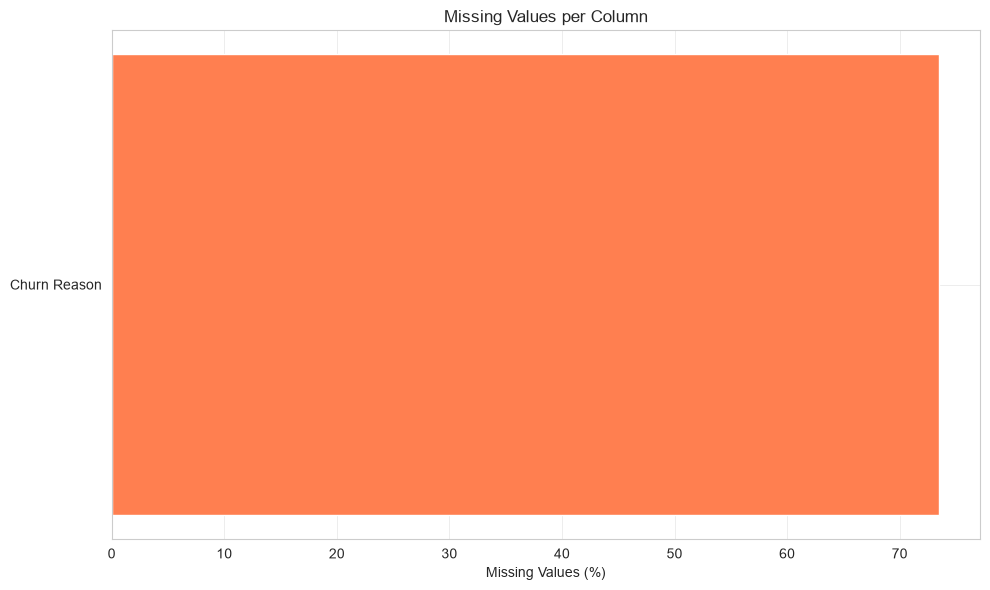

In [173]:
print("--- Missing Values ---")

missing_values = pd.DataFrame(
    {
        'Column': df.columns,
        'Missing_Count': df.isnull().sum(),
        'Percentage': ((df.isnull().sum() / len(df)) * 100).round(2)
    }
)

missing_values = missing_values[missing_values['Missing_Count'] > 0].sort_values(
    by='Percentage', ascending=False
)

if len(missing_values) > 0:
    print(missing_values)

    # Visualize
    # Visualizar missing values
    plt.figure(figsize=(10, 6))
    plt.barh(missing_values['Column'], missing_values['Percentage'], color='coral')
    plt.xlabel('Missing Values (%)')
    plt.title('Missing Values per Column')
    plt.tight_layout()
    plt.show()
else:
    print("No missing value detected!")

The only missing values are the Churn Reasons. This is fine because the dataset has a lot of customers that didn't churn and we can't expect not churning customers to have a Churn Reason.

This imposes another challenge that is to deal with the dataset unbalance due to the fact there's much more not churning customers than churning ones, as we'll see on item 3.2.

### 3.2. Target Analysis

**Objective:** Understand the target distribution and assess class balance for churn prediction.

Target distribution
Count:
target
0    5174
1    1869
Name: count, dtype: int64

Percentage:
No Churn (0): 73.46%
Churn (1): 26.54%


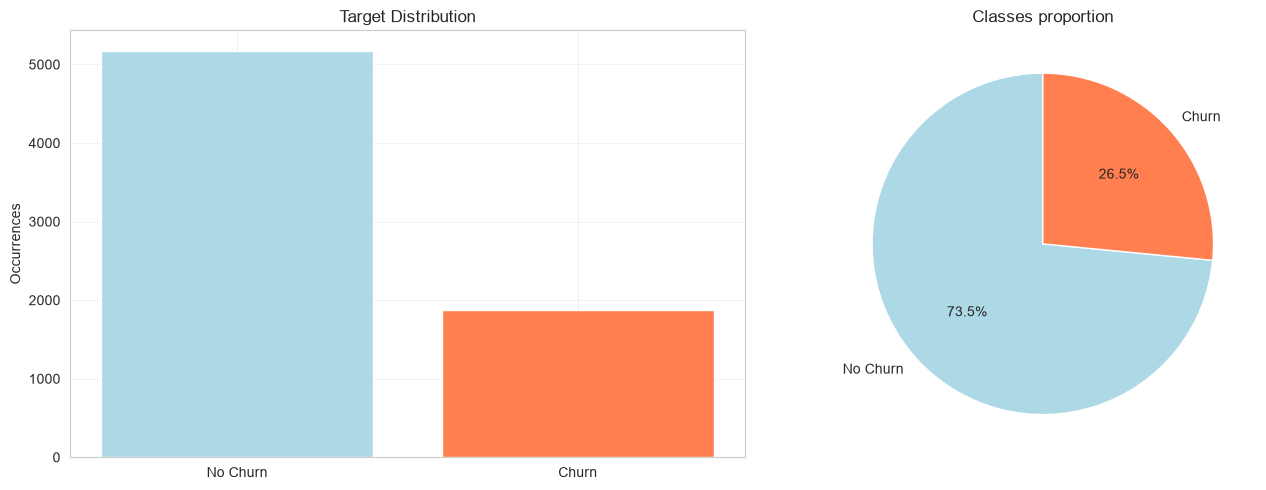


Ratio: 0.36
⚠️ Unbalanced dataset! Consider SMOTE or class_weight.


In [174]:
# Rename Churn Value column to target
df.rename(columns={'Churn Value': 'target'}, inplace=True)

print("Target distribution")
target_counts = df['target'].value_counts()
target_percentages = df['target'].value_counts(normalize=True) * 100

print("Count:")
print(target_counts)
print("\nPercentage:")
for idx, pct in target_percentages.items():
    label = "No Churn" if idx == 0 else "Churn"
    print(f"{label} ({idx}): {pct:.2f}%")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar graph
axes[0].bar(['No Churn', 'Churn'], target_counts.values, color=['lightblue', 'coral'])
axes[0].set_ylabel('Occurrences')
axes[0].set_title('Target Distribution')
axes[0].grid(axis='y', alpha=0.3)

# Pizza graph
axes[1].pie(target_counts.values, labels=['No Churn', 'Churn'],
            autopct='%1.1f%%', colors=['lightblue', 'coral'], startangle=90)
axes[1].set_title('Classes proportion')

plt.tight_layout()
plt.show()

# Check for unbalanced dataset
ratio = target_counts.min() / target_counts.max()
print(f"\nRatio: {ratio:.2f}")
if ratio < 0.5:
    print("⚠️ Unbalanced dataset! Consider SMOTE or class_weight.")
else:
    print("✓ Balanced Dataset.")

Since we have such an unbalanced dataset maybe we can pass the parameter class_weight='balanced' to scikit-learn to adjust for that.

### 3.3. Outliers

**Objective:** Identify extreme numerical observations using boxplots and z-scores.

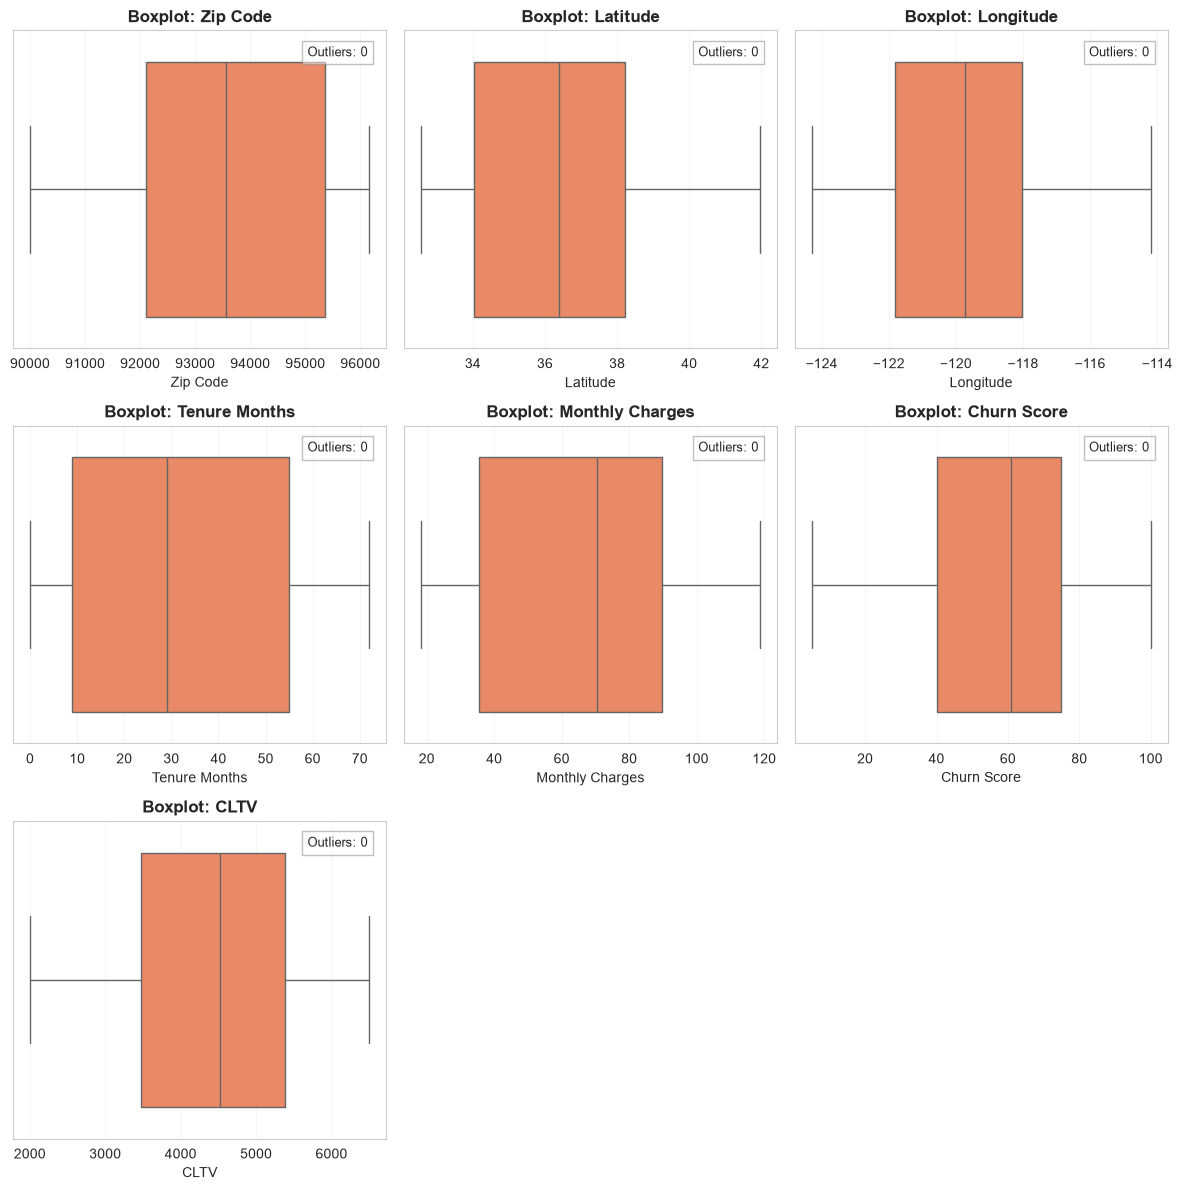

In [175]:
# Number columns (excluding Count and target)
numeric_cols = df.select_dtypes(include=[np.number]).columns
numeric_cols = numeric_cols.drop(['Count', 'target'])

n = len(numeric_cols)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.ravel()

for idx, col in enumerate(numeric_cols):
    sns.boxplot(x=df[col], ax=axes[idx], color='coral')
    axes[idx].set_title(f'Boxplot: {col}', fontweight='bold')
    axes[idx].set_xlabel(col)
    axes[idx].grid(axis='x', alpha=0.3)
    col_zscore = np.abs(stats.zscore(df[col].dropna()))
    outlier_count = (col_zscore > 3).sum()
    axes[idx].text(0.95, 0.95, f'Outliers: {outlier_count}',
                   transform=axes[idx].transAxes, fontsize=9,
                   verticalalignment='top', horizontalalignment='right',
                   bbox=dict(facecolor='white', alpha=0.5, edgecolor='gray'))

for ax in axes[n:]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

### 3.4. Anomaly Detection and Duplication

**Objective:** Detect invalid values, inconsistent records, and duplicated observations.

In [176]:
# Check for Duplicates
duplicates = df.duplicated().sum()
print(f"\n--- Duplicates ---")
print(f"Duplicate records: {duplicates}")
if duplicates > 0:
    print("⚠️ Remove the duplicates before moving ahead")

# Anomaly detection (report-only)
print("\n--- Anomaly Detection ---")
anomaly_records = []

def add_anomalies(mask, rule, column, values=None):
    mask = mask.fillna(False) if hasattr(mask, "fillna") else pd.Series(mask, index=df.index)
    for index in df.index[mask]:
        value = df.loc[index, column] if values is None else values.loc[index]
        anomaly_records.append({
            "row": index,
            "column": column,
            "rule": rule,
            "value": value
        })

# Explicit numeric domains based on the dataset's business meaning.
numeric_bounds = {
    "Count": (1, 1),
    "Zip Code": (90001, 96162),
    "Latitude": (32.5, 42.1),
    "Longitude": (-124.5, -114.0),
    "Tenure Months": (0, 72),
    "Monthly Charges": (0, 200),
    "target": (0, 1),
    "Churn Score": (0, 100),
    "CLTV": (0, 10000),
}

for column, (lower, upper) in numeric_bounds.items():
    values = pd.to_numeric(df[column], errors="coerce")
    invalid = values.notna() & ~values.between(lower, upper)
    add_anomalies(invalid, f"outside expected range [{lower}, {upper}]", column, values)
    add_anomalies(values.isna() & df[column].notna(), "non-numeric value", column)

# Total Charges is stored as text in the workbook, so validate conversion separately.
total_charges = pd.to_numeric(df["Total Charges"].astype(str).str.strip(), errors="coerce")
non_blank_total = df["Total Charges"].astype(str).str.strip().ne("")
add_anomalies(non_blank_total & total_charges.isna(), "non-blank value is not numeric", "Total Charges")
add_anomalies(total_charges.notna() & (total_charges < 0), "negative charge", "Total Charges", total_charges)
add_anomalies(non_blank_total & total_charges.notna() & (total_charges > 10000), "outside expected range [0, 10000]", "Total Charges", total_charges)
# Blank total charges are valid only for customers with zero tenure in this source.
add_anomalies(~non_blank_total & df["Tenure Months"].ne(0), "blank charges with positive tenure", "Total Charges")

# Customer identifiers and geography.
customer_id_valid = df["CustomerID"].astype(str).str.fullmatch(r"\d{4}-[A-Z0-9]{5}", na=False)
add_anomalies(~customer_id_valid, "invalid CustomerID format", "CustomerID")
add_anomalies(df["CustomerID"].duplicated(keep=False), "duplicate CustomerID", "CustomerID")
add_anomalies(df["City"].isna() | df["City"].astype(str).str.strip().eq(""), "missing city", "City")

lat_long = df["Lat Long"].astype(str).str.extract(r"^\s*([-+]?\d+(?:\.\d+)?)\s*,\s*([-+]?\d+(?:\.\d+)?)\s*$")
lat_from_text = pd.to_numeric(lat_long[0], errors="coerce")
lon_from_text = pd.to_numeric(lat_long[1], errors="coerce")
add_anomalies(lat_from_text.isna() | lon_from_text.isna(), "invalid 'Lat Long' format", "Lat Long")
add_anomalies((lat_from_text - df["Latitude"]).abs() > 1e-5, "does not match Latitude", "Lat Long")
add_anomalies((lon_from_text - df["Longitude"]).abs() > 1e-5, "does not match Longitude", "Lat Long")

# Allowed categorical domains, including fixed dataset geography.
allowed_values = {
    "Country": {"United States"},
    "State": {"California"},
    "Gender": {"Female", "Male"},
    "Senior Citizen": {"No", "Yes"},
    "Partner": {"No", "Yes"},
    "Dependents": {"No", "Yes"},
    "Phone Service": {"No", "Yes"},
    "Multiple Lines": {"No", "Yes", "No phone service"},
    "Internet Service": {"DSL", "Fiber optic", "No"},
    "Online Security": {"No", "Yes", "No internet service"},
    "Online Backup": {"No", "Yes", "No internet service"},
    "Device Protection": {"No", "Yes", "No internet service"},
    "Tech Support": {"No", "Yes", "No internet service"},
    "Streaming TV": {"No", "Yes", "No internet service"},
    "Streaming Movies": {"No", "Yes", "No internet service"},
    "Contract": {"Month-to-month", "One year", "Two year"},
    "Paperless Billing": {"No", "Yes"},
    "Payment Method": {"Bank transfer (automatic)", "Credit card (automatic)", "Electronic check", "Mailed check"},
    "Churn Label": {"No", "Yes"},
}
for column, valid_values in allowed_values.items():
    invalid = df[column].notna() & ~df[column].isin(valid_values)
    add_anomalies(invalid, f"value outside allowed domain {sorted(valid_values)}", column)
    add_anomalies(df[column].isna(), "missing categorical value", column)

# Cross-column consistency rules.
add_anomalies(df["target"].eq(1) != df["Churn Label"].eq("Yes"), "target and Churn Label disagree", "target")
churn_reason = df["Churn Reason"].astype("string").str.strip()
add_anomalies(df["Churn Label"].eq("No") & churn_reason.notna(), "Churn Reason present for non-churned customer", "Churn Reason")
add_anomalies(df["Churn Label"].eq("Yes") & (churn_reason.isna() | churn_reason.eq("")), "missing Churn Reason for churned customer", "Churn Reason")
add_anomalies(df["Phone Service"].eq("No") != df["Multiple Lines"].eq("No phone service"), "Multiple Lines inconsistent with Phone Service", "Multiple Lines")
for column in ["Online Security", "Online Backup", "Device Protection", "Tech Support", "Streaming TV", "Streaming Movies"]:
    add_anomalies(
        df["Internet Service"].eq("No") != df[column].eq("No internet service"),
        f"{column} inconsistent with Internet Service",
        column,
    )

# IQR flags supplement domain validation; they are statistical signals, not invalid values.
iqr_columns = ["Zip Code", "Latitude", "Longitude", "Tenure Months", "Monthly Charges", "Churn Score", "CLTV"]
for column in iqr_columns:
    values = pd.to_numeric(df[column], errors="coerce")
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_mask = values.notna() & ~values.between(lower, upper)
    add_anomalies(iqr_mask, f"IQR statistical flag [{lower:.2f}, {upper:.2f}]", column, values)

anomaly_report = pd.DataFrame(anomaly_records)
if anomaly_report.empty:
    print("No anomalies detected by the configured domain, consistency, or IQR checks.")
else:
    anomaly_summary = (
        anomaly_report.groupby(["column", "rule"], as_index=False)
        .agg(Records=("row", "nunique"), Examples=("value", lambda values: list(pd.Series(values).drop_duplicates().head(5))))
    )
    anomaly_summary["Percentage"] = (anomaly_summary["Records"] / len(df) * 100).round(2)
    print(f"Anomaly records: {len(anomaly_report)}")
    display(anomaly_summary.sort_values(["Records", "column"], ascending=[False, True]))
    print("\nSample anomaly records:")
    display(anomaly_report.head(20))



--- Duplicates ---
Duplicate records: 0

--- Anomaly Detection ---
No anomalies detected by the configured domain, consistency, or IQR checks.


### 3.5. Distribution Analysis

**Objective:** Understand the distribution of numerical variables and identify asymmetry.

--- DISTRIBUTION ANALYSIS ---



,Column,Skewness,Kurtosis,Interpretation
6,CLTV,-0.312,-0.934,Approximately symmetric
1,Latitude,0.304,-1.136,Approximately symmetric
0,Zip Code,-0.251,-1.154,Approximately symmetric
3,Tenure Months,0.240,-1.387,Approximately symmetric
4,Monthly Charges,-0.221,-1.257,Approximately symmetric
5,Churn Score,-0.090,-1.006,Approximately symmetric
2,Longitude,-0.041,-1.136,Approximately symmetric


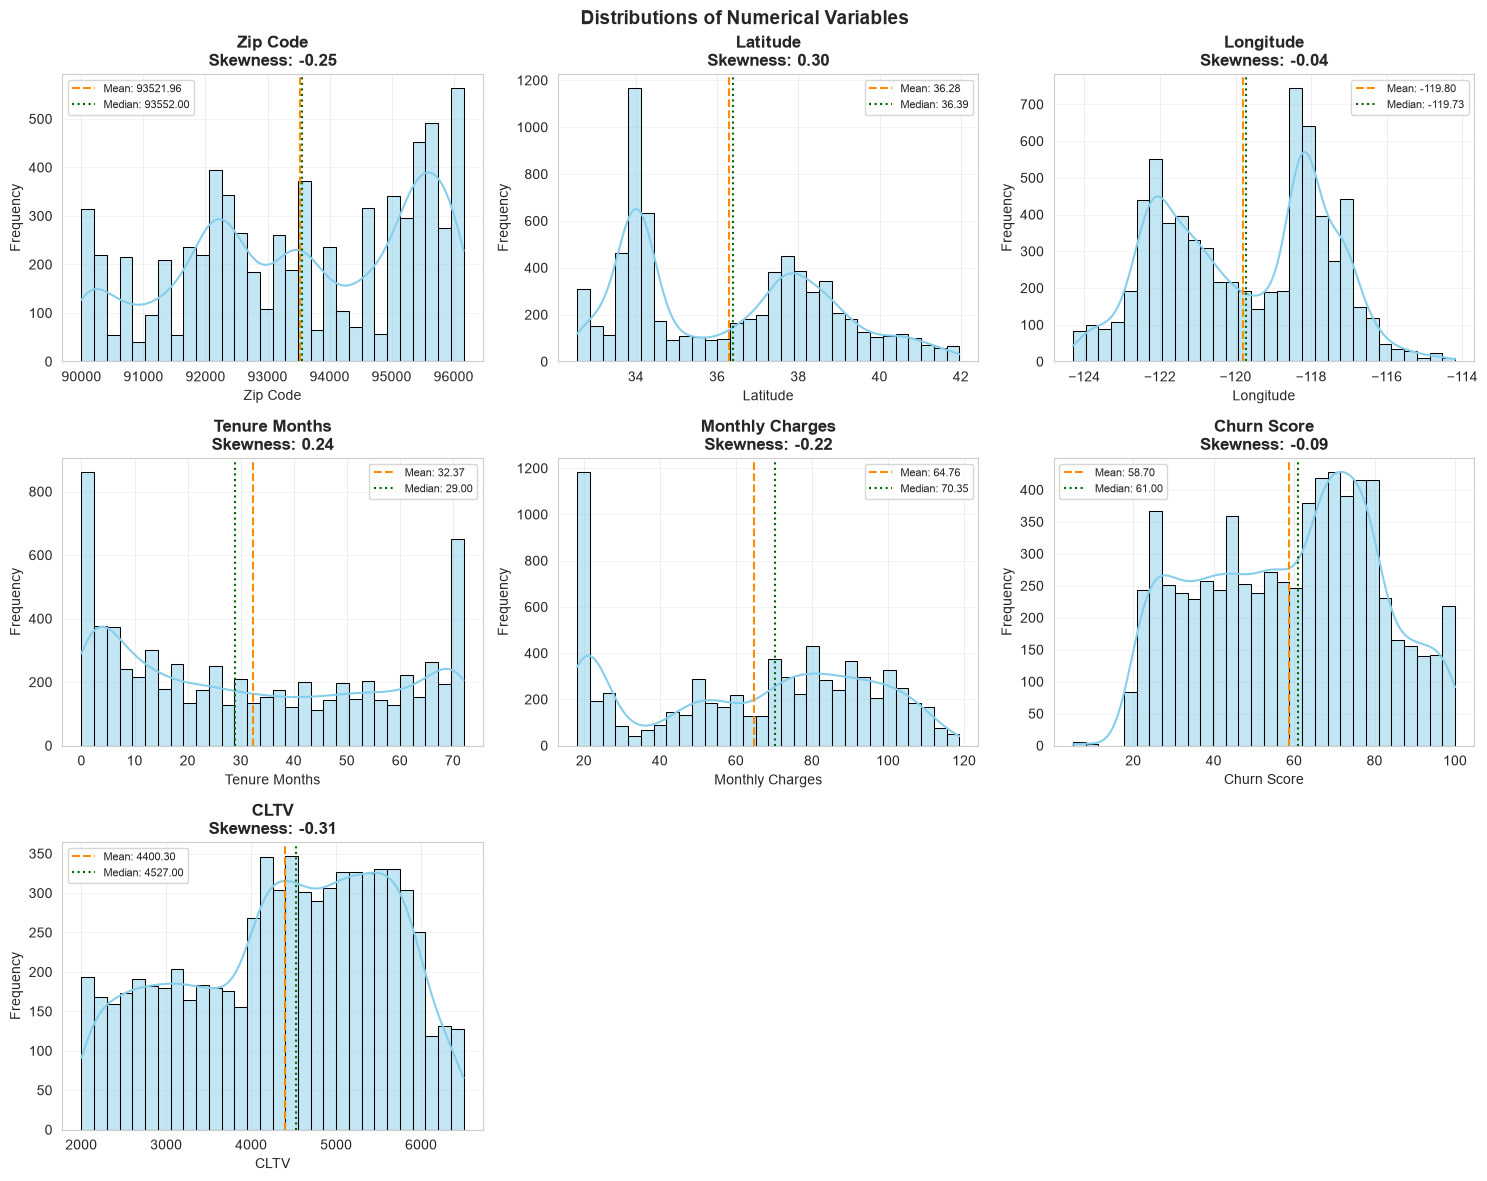

In [177]:
# Distribution analysis
print("--- DISTRIBUTION ANALYSIS ---\n")

# Use the numerical predictors already identified in section 3.3.
distribution_numeric_cols = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in ["Count", "target"]
]

distribution_stats = []
for col in distribution_numeric_cols:
    values = df[col].dropna()
    skewness = values.skew()
    kurtosis = values.kurtosis()
    if abs(skewness) < 0.5:
        interpretation = "Approximately symmetric"
    elif skewness > 0:
        interpretation = "Right-skewed"
    else:
        interpretation = "Left-skewed"
    distribution_stats.append({
        "Column": col,
        "Skewness": round(skewness, 3),
        "Kurtosis": round(kurtosis, 3),
        "Interpretation": interpretation,
    })

distribution_summary = pd.DataFrame(distribution_stats).sort_values(
    "Skewness", key=lambda values: values.abs(), ascending=False
)
display(distribution_summary)

# Visualize each numerical distribution with a histogram and density curve.
ncols = 3
nrows = int(np.ceil(len(distribution_numeric_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.atleast_1d(axes).ravel()

for idx, col in enumerate(distribution_numeric_cols):
    values = df[col].dropna()
    sns.histplot(values, bins=30, kde=True, color="skyblue", edgecolor="black", ax=axes[idx])
    axes[idx].axvline(values.mean(), color="darkorange", linestyle="--", label=f"Mean: {values.mean():.2f}")
    axes[idx].axvline(values.median(), color="darkgreen", linestyle=":", label=f"Median: {values.median():.2f}")
    axes[idx].set_title(f"{col}\nSkewness: {values.skew():.2f}", fontweight="bold")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Frequency")
    axes[idx].grid(axis="y", alpha=0.3)
    axes[idx].legend(fontsize=8)

for ax in axes[len(distribution_numeric_cols):]:
    fig.delaxes(ax)

fig.suptitle("Distributions of Numerical Variables", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### 3.6. Correlation Analysis

**Objective:** Identify relationships between numerical variables and potential multicollinearity.

=== CORRELATION ANALYSIS ===



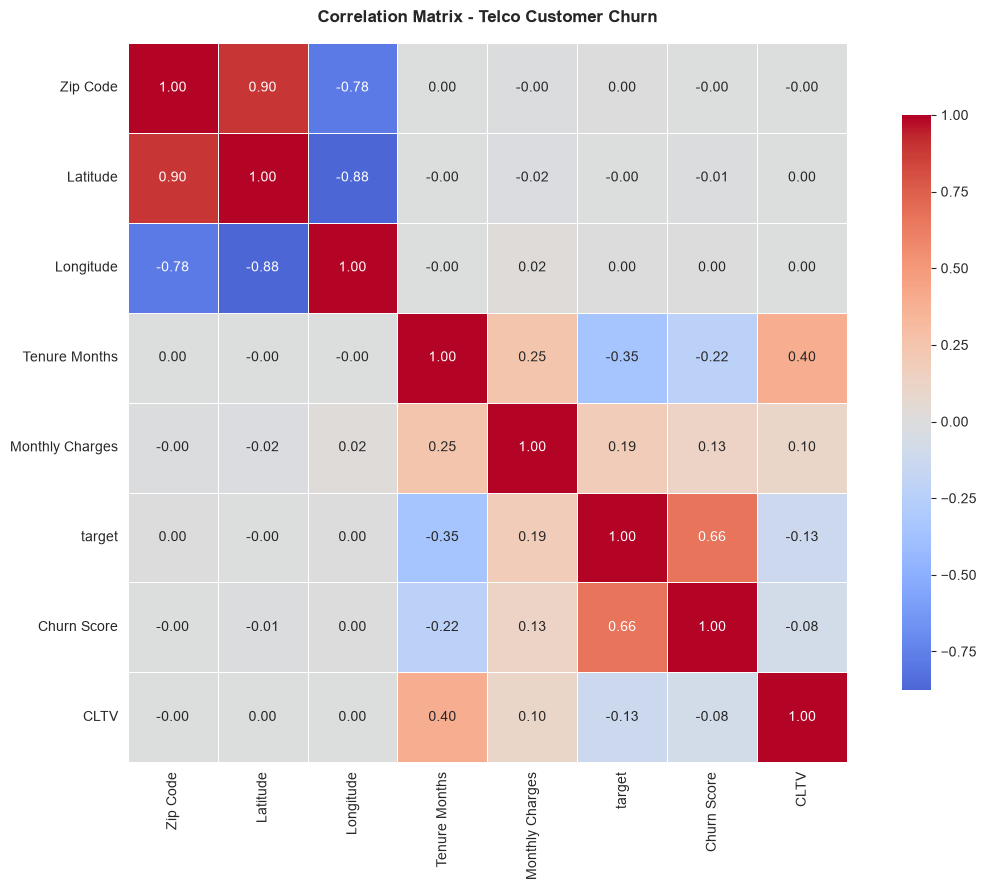

=== CORRELATIONS WITH THE TARGET ===



,Correlation with target
Churn Score,0.664897
Tenure Months,-0.352229
Monthly Charges,0.193356
CLTV,-0.127463
Longitude,0.004594
Latitude,-0.003384
Zip Code,0.003346



=== FEATURE MULTICOLLINEARITY ===


,Feature 1,Feature 2,Correlation
0,Zip Code,Latitude,0.896
2,Latitude,Longitude,-0.877
1,Zip Code,Longitude,-0.784



Potentially collinear feature pairs (|correlation| >= 0.70): 3


In [178]:
# Correlation analysis
print("=== CORRELATION ANALYSIS ===\n")

# Exclude the constant Count field and keep the target for target-relationship analysis.
correlation_cols = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col != "Count"
]
corr_numeric = df[correlation_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_numeric,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)
plt.title("Correlation Matrix - Telco Customer Churn", fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

print("=== CORRELATIONS WITH THE TARGET ===\n")
target_correlations = corr_numeric["target"].drop("target").sort_values(key=lambda values: values.abs(), ascending=False)
display(target_correlations.rename("Correlation with target").to_frame())

# Identify highly correlated predictor pairs that may indicate multicollinearity.
print("\n=== FEATURE MULTICOLLINEARITY ===")
correlation_threshold = 0.70
feature_corr = corr_numeric.drop(index="target", columns="target")
high_corr_pairs = []
for i, first_feature in enumerate(feature_corr.columns):
    for second_feature in feature_corr.columns[i + 1:]:
        correlation = feature_corr.loc[first_feature, second_feature]
        if abs(correlation) >= correlation_threshold:
            high_corr_pairs.append({
                "Feature 1": first_feature,
                "Feature 2": second_feature,
                "Correlation": round(correlation, 3),
            })

if high_corr_pairs:
    high_corr_df = pd.DataFrame(high_corr_pairs)
    high_corr_df["Absolute correlation"] = high_corr_df["Correlation"].abs()
    high_corr_df = high_corr_df.sort_values("Absolute correlation", ascending=False).drop(columns="Absolute correlation")
    display(high_corr_df)
    print(f"\nPotentially collinear feature pairs (|correlation| >= {correlation_threshold:.2f}): {len(high_corr_df)}")
else:
    print(f"No feature pairs with |correlation| >= {correlation_threshold:.2f} were detected.")


## 4. Data Preprocessing

### 4.1 Missing Values
As stated on 3.1 the only column missing values is Churn Reason. This happens because the dataset has users that didn't churn. If the dataset had only churning customers and missing reasons this would pose a problem. But we are not interested on predicting churn reasons, instead we want to predict if churn will happen. So it's expected to have churning and not churning customers, as we do.

Because of this, we won't have any actions on these missing values for now. We'll just discard this column from the training data since it doesn't affect the target variable at all. We will have to understand if using all dataset will give us better results than to discarting part of the non-churning customers to seek out for a more balanced dataset.

### 4.2. One-hot encoding


In [179]:
# One-hot encoding of categorical predictors
categorical_cols = [
    "Gender",
    "Senior Citizen",
    "Partner",
    "Dependents",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies",
    "Contract",
    "Paperless Billing",
    "Payment Method",
]

# Churn Reason is target-derived and is excluded from the feature dataframe.
df_encoded = df.drop(columns=["Churn Reason"]).copy()
df_encoded = pd.get_dummies(
    df_encoded,
    columns=categorical_cols,
    drop_first=True,
    dtype=int,
)

print(f"Original shape: {df.shape}")
print(f"Shape after one-hot encoding: {df_encoded.shape}")
print("\nEncoded columns:")
print([col for col in df_encoded.columns if any(col.startswith(f"{category}_") for category in categorical_cols)])
display(df_encoded.head())


Original shape: (7043, 33)
Shape after one-hot encoding: (7043, 43)

Encoded columns:
['Gender_Male', 'Senior Citizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'Phone Service_Yes', 'Multiple Lines_No phone service', 'Multiple Lines_Yes', 'Internet Service_Fiber optic', 'Internet Service_No', 'Online Security_No internet service', 'Online Security_Yes', 'Online Backup_No internet service', 'Online Backup_Yes', 'Device Protection_No internet service', 'Device Protection_Yes', 'Tech Support_No internet service', 'Tech Support_Yes', 'Streaming TV_No internet service', 'Streaming TV_Yes', 'Streaming Movies_No internet service', 'Streaming Movies_Yes', 'Contract_One year', 'Contract_Two year', 'Paperless Billing_Yes', 'Payment Method_Credit card (automatic)', 'Payment Method_Electronic check', 'Payment Method_Mailed check']


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Tenure Months,...,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Paperless Billing_Yes,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,2,...,0,0,0,0,0,0,1,0,0,1
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,2,...,0,0,0,0,0,0,1,0,1,0
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,8,...,0,1,0,1,0,0,1,0,1,0
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,28,...,0,1,0,1,0,0,1,0,1,0
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,49,...,0,1,0,1,0,0,1,0,0,0


### Why one-hot encoding was used

The categorical columns were converted into indicator columns instead of being represented with numeric codes such as `0`, `1`, and `2`. Numeric codes can create an artificial order between categories. For example, assigning `No internet service = 2` would incorrectly suggest that it is greater than `Yes = 1`, even though these are nominal categories rather than measurements.

With `drop_first=True`, one category from each field is used as the reference category. Therefore, the encoding does not create unnecessary duplicate information while still allowing the model to learn a separate effect for each remaining category.

The following fields were expanded because they contain more than two categories:

| Original column | Categories represented | Why the distinction matters |
|---|---|---|
| `Multiple Lines` | `No`, `Yes`, `No phone service` | Separates customers with no additional line from customers without phone service. |
| `Internet Service` | `DSL`, `Fiber optic`, `No` | Distinguishes the internet technology from customers without internet service. |
| `Online Security` | `No`, `Yes`, `No internet service` | Distinguishes not subscribing from the service being unavailable. |
| `Online Backup` | `No`, `Yes`, `No internet service` | Distinguishes not subscribing from the service being unavailable. |
| `Device Protection` | `No`, `Yes`, `No internet service` | Distinguishes not subscribing from the service being unavailable. |
| `Tech Support` | `No`, `Yes`, `No internet service` | Distinguishes not subscribing from the service being unavailable. |
| `Streaming TV` | `No`, `Yes`, `No internet service` | Distinguishes not subscribing from the service being unavailable. |
| `Streaming Movies` | `No`, `Yes`, `No internet service` | Indicates that streaming is unavailable, not that the customer streams without internet. |
| `Contract` | `Month-to-month`, `One year`, `Two year` | Contract types are nominal choices, not numeric levels. |
| `Payment Method` | Four payment methods | Payment methods have no natural numeric order. |

The binary fields (`Gender`, `Senior Citizen`, `Partner`, `Dependents`, `Phone Service`, and `Paperless Billing`) produce one indicator column each because their omitted category is represented by zero in the reference encoding. `Churn Reason` was excluded because it is target-derived and would cause data leakage when predicting churn.


### 4.3. City Frequency Encoding

**Objective:** Convert the high-cardinality `City` column into a numeric feature without creating one-hot columns for all 1,129 city values.

In [180]:
# Frequency encoding for the high-cardinality City column
city_frequency = df["City"].value_counts(normalize=True)
df_encoded["City_Frequency"] = df["City"].map(city_frequency)
df_encoded = df_encoded.drop(columns=["City"])

print(f"Unique cities: {df['City'].nunique()}")
print("City frequency range: "
      f"{df_encoded['City_Frequency'].min():.6f} to "
      f"{df_encoded['City_Frequency'].max():.6f}")
print("\nMost frequent cities:")
display(city_frequency.head(10).rename("Frequency").to_frame())
display(df_encoded[["City_Frequency"]].head())


Unique cities: 1129
City frequency range: 0.000568 to 0.043305

Most frequent cities:


,Frequency
City,
Los Angeles,0.043305
San Diego,0.021298
San Jose,0.015902
Sacramento,0.015334
San Francisco,0.014766
Fresno,0.009087
Long Beach,0.008519
Oakland,0.007383
Stockton,0.006247


,City_Frequency
0,0.043305
1,0.043305
2,0.043305
3,0.043305
4,0.043305


Frequency encoding represents each city by its proportion of records in the dataset. This reduces the 1,129 city categories to one numeric feature while preserving how common each city is. The encoding is based only on city frequency, not on the churn target, so it does not introduce target leakage. The original `City` column is removed from `df_encoded` after `City_Frequency` is created.

### 4.4. Geographic Field Preparation

**Objective:** Remove the redundant text representation of geographic coordinates before model training.

In [181]:
# Remove the redundant Lat Long text field
# Latitude and Longitude are retained as numeric features.
df_encoded = df_encoded.drop(columns=["Lat Long"])

print("Removed column: Lat Long")
print("Retained numeric geographic columns: Latitude, Longitude")
print(f"Modeling dataframe shape: {df_encoded.shape}")
print("Non-numeric columns remaining in df_encoded:")
print(df_encoded.select_dtypes(exclude=[np.number]).columns.tolist())


Removed column: Lat Long
Retained numeric geographic columns: Latitude, Longitude
Modeling dataframe shape: (7043, 42)
Non-numeric columns remaining in df_encoded:
['CustomerID', 'Country', 'State', 'Total Charges', 'Churn Label']


`Lat Long` contains the same geographic information already available in the numeric `Latitude` and `Longitude` columns, but stores it as a text string such as `32.802959, -117.027095`. Keeping it would duplicate information and prevent scikit-learn estimators from treating the complete feature matrix as numeric.

The string field is therefore removed from `df_encoded`, while `Latitude` and `Longitude` are retained as numeric features. This preserves the geographic signal without adding a redundant representation. `CustomerID`, `Country`, and `State` remain excluded later in the modeling feature-selection step because they are identifiers or constant fields.

### 4.5. Final Feature Preparation

**Objective:** Ensure the modeling dataframe contains only valid numeric predictors and one target column before training.

In [182]:
# Final numeric feature preparation before modeling
# Total Charges is stored as text and contains blanks for zero-tenure customers.
total_charges = pd.to_numeric(
    df_encoded["Total Charges"].astype(str).str.strip(),
    errors="coerce",
)
df_encoded["Total Charges"] = total_charges.fillna(0)

# Churn Label duplicates the binary target and must not be used as a predictor.
df_encoded = df_encoded.drop(columns=["Churn Label"])

print("Converted Total Charges to numeric; blank values were set to 0.")
print("Removed duplicated target field: Churn Label")
print("Non-numeric columns remaining in df_encoded:")
print(df_encoded.select_dtypes(exclude=[np.number]).columns.tolist())


Converted Total Charges to numeric; blank values were set to 0.
Removed duplicated target field: Churn Label
Non-numeric columns remaining in df_encoded:
['CustomerID', 'Country', 'State']


`Total Charges` is numeric data stored as text in the workbook. Its blank values correspond to customers with zero months of tenure, so they are converted to `0` after numeric coercion. `Churn Label` is removed because it expresses the same outcome as the binary `target` column; retaining it would duplicate the target and cause leakage.

## 5. MVP experiments

### 5.1. Logistic regression

In [183]:
from pathlib import Path

import mlflow

# Keep MLflow paths independent of PyCharm's notebook working-directory setting.
working_dir = Path.cwd().resolve()
if (working_dir / "data").is_dir() and (working_dir / "notebooks").is_dir():
    project_dir = working_dir
elif working_dir.name == "notebooks" and (working_dir.parent / "data").is_dir():
    project_dir = working_dir.parent
else:
    project_dir = next(
        parent for parent in (working_dir, *working_dir.parents)
        if (parent / "data").is_dir() and (parent / "notebooks").is_dir()
    )
tracking_dir = project_dir / ".mlflow"
artifact_dir = tracking_dir / "artifacts"
tracking_dir.mkdir(parents=True, exist_ok=True)
artifact_dir.mkdir(parents=True, exist_ok=True)
database_path = tracking_dir / "mlflow.db"
if database_path.exists():
    database_path.chmod(0o664)
tracking_uri = f"sqlite:///{database_path}"
if mlflow.active_run() is not None:
    mlflow.end_run()
mlflow.set_tracking_uri(tracking_uri)
print(f"MLflow project directory: {project_dir}")
print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")
print(f"MLflow artifact directory: {artifact_dir}")


MLflow project directory: /Users/falcon/Developer/FIAP-mle/tech-challenge-fase1
MLflow tracking URI: sqlite:////Users/falcon/Developer/FIAP-mle/tech-challenge-fase1/.mlflow/mlflow.db
MLflow artifact directory: /Users/falcon/Developer/FIAP-mle/tech-challenge-fase1/.mlflow/artifacts


In [184]:
X = df_encoded.drop(columns=['CustomerID', 'Count', 'Country', 'State', 'target'])
y = df_encoded['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [185]:
import mlflow
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Configure tracking here so this block is safe to run independently in PyCharm.
working_dir = Path.cwd().resolve()
if (working_dir / "data").is_dir() and (working_dir / "notebooks").is_dir():
    project_dir = working_dir
elif working_dir.name == "notebooks" and (working_dir.parent / "data").is_dir():
    project_dir = working_dir.parent
else:
    project_dir = next(
        parent for parent in (working_dir, *working_dir.parents)
        if (parent / "data").is_dir() and (parent / "notebooks").is_dir()
    )
tracking_dir = project_dir / ".mlflow"
artifact_dir = tracking_dir / "artifacts"
tracking_dir.mkdir(parents=True, exist_ok=True)
artifact_dir.mkdir(parents=True, exist_ok=True)
database_path = tracking_dir / "mlflow.db"
if database_path.exists():
    database_path.chmod(0o664)
tracking_uri = f"sqlite:///{database_path}"
if mlflow.active_run() is not None:
    mlflow.end_run()
mlflow.set_tracking_uri(tracking_uri)
print(f"MLflow project directory: {project_dir}")
print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")
print(f"MLflow artifact directory: {artifact_dir}")

experiment_name = "telco_churn_logistic_regression_full"
experiment = mlflow.get_experiment_by_name(experiment_name)
if experiment is None or not str(experiment.artifact_location).startswith(str(artifact_dir)):
    experiment_name = "telco_churn_logistic_regression_full_local"
    if mlflow.get_experiment_by_name(experiment_name) is None:
        mlflow.create_experiment(experiment_name, artifact_location=str(artifact_dir))
mlflow.set_experiment(experiment_name)

with mlflow.start_run(run_name='logistic_regression_baseline'):
    model = LogisticRegression(random_state=42)
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    test_f1 = f1_score(y_test, y_pred_test)
    test_precision = precision_score(y_test, y_pred_test)
    test_recall = recall_score(y_test, y_pred_test)

    mlflow.log_metric("train_accuracy", train_accuracy)
    mlflow.log_metric("test_accuracy", test_accuracy)
    mlflow.log_metric("test_f1_score", test_f1)
    mlflow.log_metric("test_precision", test_precision)
    mlflow.log_metric("test_recall", test_recall)

    overfitting = train_accuracy - test_accuracy
    mlflow.log_metric("overfitting", overfitting)

    mlflow.sklearn.log_model(model, name="model")

    print(f"=== LOGISTIC REGRESSION ===")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Test Accuracy:  {test_accuracy:.4f}")
    print(f"Test F1 Score:  {test_f1:.4f}")

    print(f"Test Precision: {test_precision:.4f}")
    print(f"Test Recall:    {test_recall:.4f}")
    print(f"Overfitting:    {overfitting:.4f}")

2026/11/02 15:41:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/02 15:41:44 INFO mlflow.store.db.utils: Updating database tables


MLflow project directory: /Users/falcon/Developer/FIAP-mle/tech-challenge-fase1
MLflow tracking URI: sqlite:////Users/falcon/Developer/FIAP-mle/tech-challenge-fase1/.mlflow/mlflow.db
MLflow artifact directory: /Users/falcon/Developer/FIAP-mle/tech-challenge-fase1/.mlflow/artifacts
=== LOGISTIC REGRESSION ===
Train Accuracy: 0.9104
Test Accuracy:  0.8850
Test F1 Score:  0.7944
Test Precision: 0.8067
Test Recall:    0.7825
Overfitting:    0.0253


## 6. Persist dataframe


In [186]:
df_encoded.to_csv('../data/telco_full_encoded.csv', index=False)

## 7. Persist model


In [187]:
# Reapply the same writable tracking URI when this block is run independently.
from pathlib import Path
import mlflow

working_dir = Path.cwd().resolve()
if (working_dir / "data").is_dir() and (working_dir / "notebooks").is_dir():
    project_dir = working_dir
elif working_dir.name == "notebooks" and (working_dir.parent / "data").is_dir():
    project_dir = working_dir.parent
else:
    project_dir = next(
        parent for parent in (working_dir, *working_dir.parents)
        if (parent / "data").is_dir() and (parent / "notebooks").is_dir()
    )
tracking_dir = project_dir / ".mlflow"
artifact_dir = tracking_dir / "artifacts"
tracking_dir.mkdir(parents=True, exist_ok=True)
artifact_dir.mkdir(parents=True, exist_ok=True)
database_path = tracking_dir / "mlflow.db"
if database_path.exists():
    database_path.chmod(0o664)
if mlflow.active_run() is not None:
    mlflow.end_run()
mlflow.set_tracking_uri(f"sqlite:///{database_path}")
mlflow.sklearn.log_model(model, name="telco_full_logistic_regression_model")

import joblib
joblib.dump(model, project_dir / 'models' / 'telco_full_logistic_regression_model.joblib')


['/Users/falcon/Developer/FIAP-mle/tech-challenge-fase1/models/telco_full_logistic_regression_model.joblib']